# Notebook 01 | EDA & Data Preparation
**Global Superstore – Customer Segmentation & Behavioral Analytics**

**Goal:** understand the raw transaction data, check its quality, and build the customer-level dataset used by the rest of the project.

| | |
|---|---|
| **Input** | PostgreSQL table `retail_raw` (51,290 transaction lines, 27 fields) |
| **Output** | `customer_features.csv` – one row per customer (4,873 rows) |
| **Next** | `02_Statistical_Analysis.ipynb`, `03_Customer_Segmentation.ipynb` |

**Sections**
1. Setup and data loading
2. First look at the raw data
3. Data quality checks (missing values, duplicates, dates, numeric ranges, categories)
4. Transaction-level distributions
5. Building the customer-level dataset (SQL)
6. Customer-level EDA (integrity checks, distributions, relationships)
7. Export for the next notebooks

> Set the database credentials as environment variables (`PGUSER`, `PGPASSWORD`, `PGDATABASE`) before running.

## 1. Setup and data loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Connect to PostgreSQL. Credentials come from environment variables so no password is stored in the notebook.

In [3]:
import os
from sqlalchemy import create_engine, URL

# Credentials are read from environment variables - never hard-code passwords in a repo.
db_url = URL.create(
    drivername="postgresql+psycopg",
    username=os.getenv("PGUSER", "postgres"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST", "127.0.0.1"),
    port=int(os.getenv("PGPORT", 5432)),
    database=os.getenv("PGDATABASE", "superstore_project"),
)
engine = create_engine(db_url)
print("Database engine created successfully!")

Database engine created successfully!


Load the full raw table into a DataFrame (`df`). Row grain = one transaction line.

In [5]:
query = """
SELECT *
FROM retail_raw;
"""

df = pd.read_sql(query, engine)

print("Data loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Data loaded successfully!
Rows: 51290
Columns: 27


## 2. First look at the raw data

In [6]:
df.head()

,category,city,country,customer_id,customer_name,discount,market,record_count,order_date,order_id,...,sales,segment,ship_date,ship_mode,shipping_cost,state,sub_category,year,market2,week_num
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07,CA-2011-130813,...,19.0,Consumer,2011-01-09,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21,CA-2011-148614,...,19.0,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05,CA-2011-118962,...,21.0,Consumer,2011-08-09,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05,CA-2011-118962,...,111.0,Consumer,2011-08-09,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29,CA-2011-146969,...,6.0,Consumer,2011-10-03,Standard Class,1.32,California,Paper,2011,North America,40


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   category        51290 non-null  str    
 1   city            51290 non-null  str    
 2   country         51290 non-null  str    
 3   customer_id     51290 non-null  str    
 4   customer_name   51290 non-null  str    
 5   discount        51290 non-null  float64
 6   market          51290 non-null  str    
 7   record_count    51290 non-null  int64  
 8   order_date      51290 non-null  object 
 9   order_id        51290 non-null  str    
 10  order_priority  51290 non-null  str    
 11  product_id      51290 non-null  str    
 12  product_name    51290 non-null  str    
 13  profit          51290 non-null  float64
 14  quantity        51290 non-null  int64  
 15  region          51290 non-null  str    
 16  row_id          51290 non-null  int64  
 17  sales           51290 non-null  float64
 1

In [8]:
df.describe()

,discount,record_count,profit,quantity,row_id,sales,shipping_cost,year,week_num
count,51290.000000,51290.0,51290.000000,51290.000000,51290.00000,51290.000000,51290.000000,51290.000000,51290.000000
mean,0.142908,1.0,28.610982,3.476545,25645.50000,246.498440,26.375818,2012.777208,31.287112
std,0.212280,0.0,174.340972,2.278766,14806.29199,487.567175,57.296810,1.098931,14.429795
min,0.000000,1.0,-6599.978000,1.000000,1.00000,0.000000,0.002000,2011.000000,1.000000
25%,0.000000,1.0,0.000000,2.000000,12823.25000,31.000000,2.610000,2012.000000,20.000000
50%,0.000000,1.0,9.240000,3.000000,25645.50000,85.000000,7.790000,2013.000000,33.000000
75%,0.200000,1.0,36.810000,5.000000,38467.75000,251.000000,24.450000,2014.000000,44.000000
max,0.850000,1.0,8399.976000,14.000000,51290.00000,22638.000000,933.570000,2014.000000,53.000000


## 3. Data quality checks
Rule followed throughout: **investigate before removing**. Negative profit is a business outcome (discount-driven loss), not an error.

### 3.1 Missing values and duplicates

In [9]:
# Missing values per column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values by column:
Series([], dtype: int64)

Total missing values: 0


In [10]:
# Checking duplicate rows
print("Total rows:", len(df))
print("Completely duplicated rows:", df.duplicated().sum())

Total rows: 51290
Completely duplicated rows: 0


### 3.2 Dates
Convert to datetime, then check that no order ships before it is placed.

In [11]:
df[["customer_id", "order_id", "order_date", "ship_date",
    "sales", "profit", "discount", "quantity"]].dtypes

customer_id        str
order_id           str
order_date      object
ship_date       object
sales          float64
profit         float64
discount       float64
quantity         int64
dtype: object

In [12]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

print(df[["order_date", "ship_date"]].dtypes)

order_date    datetime64[s]
ship_date     datetime64[s]
dtype: object


In [13]:
df[["order_date", "ship_date"]].describe()

,order_date,ship_date
count,51290,51290
mean,2013-05-11 21:26:49,2013-05-15 20:42:42
min,2011-01-01 00:00:00,2011-01-03 00:00:00
25%,2012-06-19 00:00:00,2012-06-23 00:00:00
50%,2013-07-08 00:00:00,2013-07-12 00:00:00
75%,2014-05-22 00:00:00,2014-05-26 00:00:00
max,2014-12-31 00:00:00,2015-01-07 00:00:00


In [14]:
# Calculate days between order and shipment
df["ship_days"] = (df["ship_date"] - df["order_date"]).dt.days

# Inspect shipping duration
print("Minimum shipping days:", df["ship_days"].min())
print("Maximum shipping days:", df["ship_days"].max())
print("Negative shipping durations:", (df["ship_days"] < 0).sum())
print("Same-day shipments:", (df["ship_days"] == 0).sum())

df["ship_days"].describe()

Minimum shipping days: 0
Maximum shipping days: 7
Negative shipping durations: 0
Same-day shipments: 2600


count    51290.000000
mean         3.969370
std          1.729437
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          7.000000
Name: ship_days, dtype: float64

### 3.3 Numeric sanity checks
Looking for impossible values (negative quantity, discount outside 0–1, negative shipping cost). Only one line has `sales <= 0`; it is kept and documented. Loss-making lines (12,544, about 24.5%) are kept as real business outcomes.

In [16]:
print("Sales <= 0:", (df["sales"] <= 0).sum())   # only one suspicious line (inspected below)
print("Negative profit:", (df["profit"] < 0).sum())
print("Zero profit:", (df["profit"] == 0).sum())
print("Negative quantity:", (df["quantity"] < 0).sum())
print("Negative discount:", (df["discount"] < 0).sum())
print("Discount above 1:", (df["discount"] > 1).sum())
print("Negative shipping cost:", (df["shipping_cost"] < 0).sum())

Sales <= 0: 1
Negative profit: 12544
Zero profit: 668
Negative quantity: 0
Negative discount: 0
Discount above 1: 0
Negative shipping cost: 0


In [17]:
df.loc[
    df["sales"] <= 0,
    [
        "row_id",
        "order_id",
        "customer_id",
        "product_name",
        "sales",
        "profit",
        "quantity",
        "discount"
    ]
]

,row_id,order_id,customer_id,product_name,sales,profit,quantity,discount
46158,35398,US-2014-102288,ZC-219104,Hoover Replacement Belt for Commercial Guardsm...,0.0,-1.11,1,0.8


### 3.4 Categorical columns
Check the number of levels and the spelling/consistency of each label.

In [18]:
categorical_columns = [
    "category",
    "market",
    "segment",
    "region",
    "ship_mode",
    "order_priority"
]

for column in categorical_columns:
    print(f"\n--- {column.upper()} ---")
    print("Unique values:", df[column].nunique())
    print(df[column].value_counts(dropna=False))


--- CATEGORY ---
Unique values: 3
category
Office Supplies    31273
Technology         10141
Furniture           9876
Name: count, dtype: int64

--- MARKET ---
Unique values: 7
market
APAC      11002
LATAM     10294
EU        10000
US         9994
EMEA       5029
Africa     4587
Canada      384
Name: count, dtype: int64

--- SEGMENT ---
Unique values: 3
segment
Consumer       26518
Corporate      15429
Home Office     9343
Name: count, dtype: int64

--- REGION ---
Unique values: 13
region
Central           11117
South              6645
EMEA               5029
North              4785
Africa             4587
Oceania            3487
West               3203
Southeast Asia     3129
East               2848
North Asia         2338
Central Asia       2048
Caribbean          1690
Canada              384
Name: count, dtype: int64

--- SHIP_MODE ---
Unique values: 4
ship_mode
Standard Class    30775
Second Class      10309
First Class        7505
Same Day           2701
Name: count, dtype: int64

## 4. Transaction-level distributions
Percentiles and skewness first, then charts. All five numeric variables are **right-skewed** (long tail of large values), so the "central 99%" plots are used to see the bulk of the data without extreme values hiding the shape.

In [19]:
numeric_columns =[
    'sales',
    'profit',
    'quantity',
    'discount',
    'shipping_cost'
]

df[numeric_columns].describe(
    percentiles=[0.01,0.50,0.99]
)

,sales,profit,quantity,discount,shipping_cost
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.498440,28.610982,3.476545,0.142908,26.375818
std,487.567175,174.340972,2.278766,0.212280,57.296810
min,0.000000,-6599.978000,1.000000,0.000000,0.002000
1%,4.000000,-351.505650,1.000000,0.000000,0.200000
50%,85.000000,9.240000,3.000000,0.000000,7.790000
99%,2301.000000,587.359950,11.000000,0.700000,286.754300
max,22638.000000,8399.976000,14.000000,0.850000,933.570000


In [20]:
# Calculate skewness

df[numeric_columns].skew().sort_values(ascending=False)

#All five numerical variables have positive skewness, meaning their distributions have longer tails toward larger values.

sales            8.137981
shipping_cost    5.863225
profit           4.157189
discount         1.387775
quantity         1.360368
dtype: float64

**Sales**

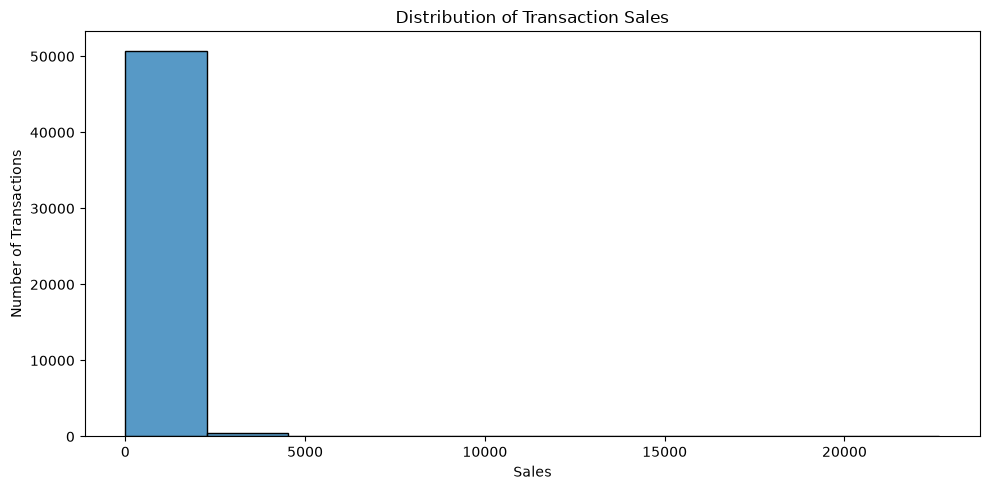

In [ ]:
# Visualize the distributions
# sales distribution

plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='sales',
    bins=10
)

plt.title("Distribution of Transaction Sales")
plt.xlabel("Sales")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

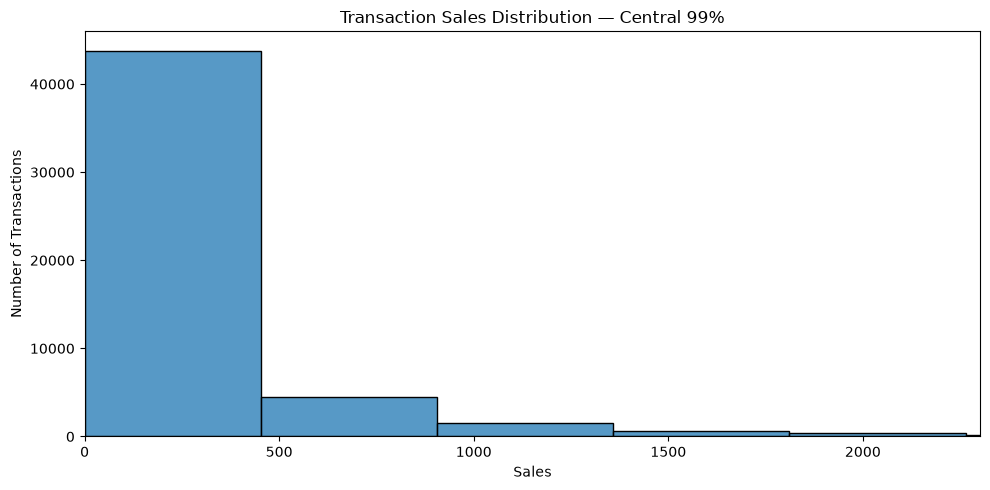

In [24]:
sales_p99 = df["sales"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="sales",
    bins=50
)

plt.xlim(0, sales_p99)

plt.title("Transaction Sales Distribution — Central 99%")
plt.xlabel("Sales")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

**Profit** (red dashed line = break-even; everything left of it is a loss)

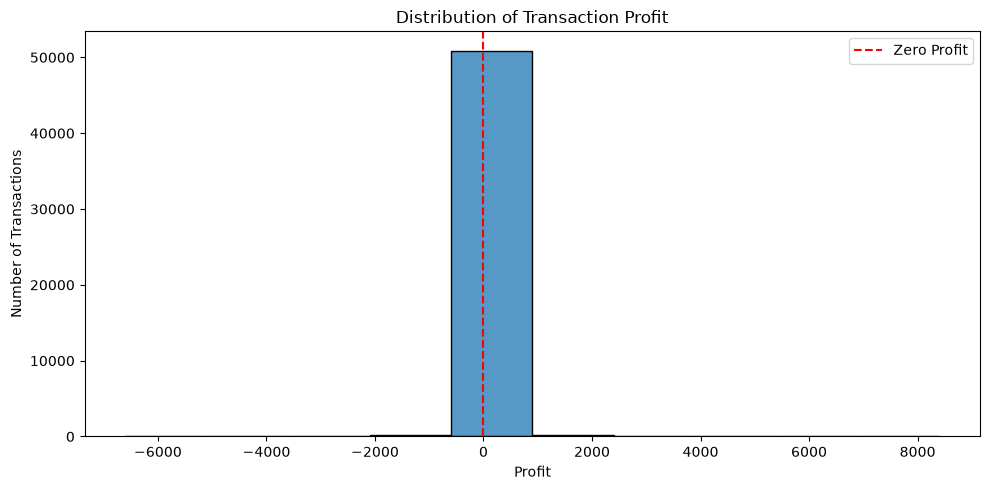

In [26]:
# profit distribution

plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='profit',
    bins=10
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Profit"
)

plt.title("Distribution of Transaction Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Transactions")
plt.legend()

plt.tight_layout()

plt.show()

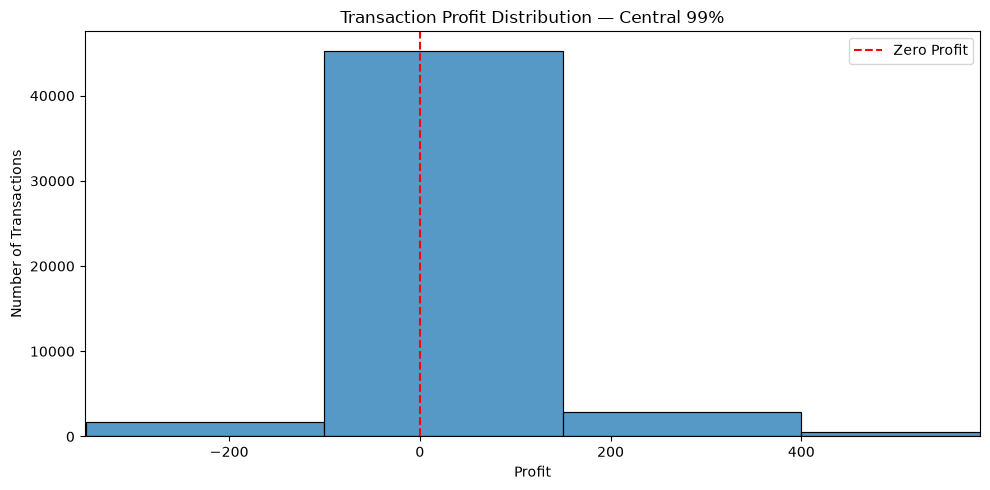

In [27]:
profit_p01 = df["profit"].quantile(0.01)
profit_p99 = df["profit"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="profit",
    bins=60
)

plt.xlim(profit_p01, profit_p99)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Profit"
)

plt.title("Transaction Profit Distribution — Central 99%")
plt.xlabel("Profit")
plt.ylabel("Number of Transactions")
plt.legend()

plt.tight_layout()
plt.show()

**Quantity, discount and shipping cost**

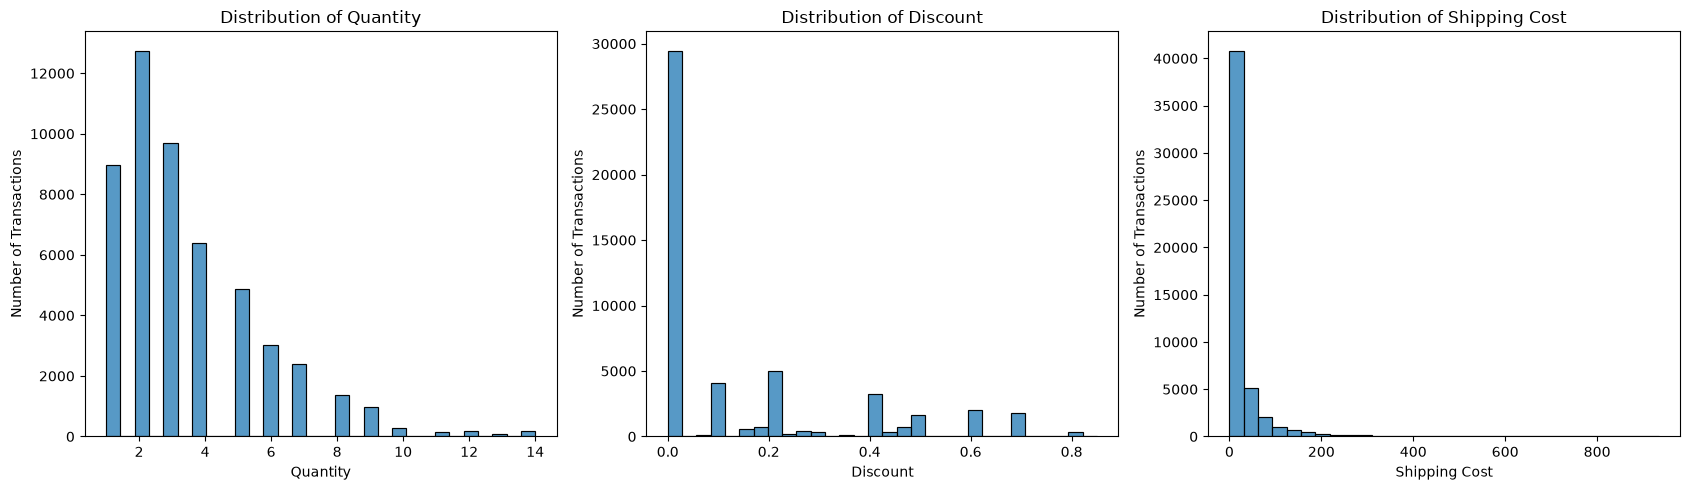

In [28]:
columns = [
    "quantity",
    "discount",
    "shipping_cost"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for column, ax in zip(columns, axes):
    sns.histplot(
        data=df,
        x=column,
        bins=30,
        ax=ax
    )

    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

## 5. Building the customer-level dataset
One row per customer, built in SQL (same logic as the `customer_features` view in `sql/02_customer_features_and_rfm.sql`):
orders, sales, profit, quantity, AOV, items and profit per order, first/last purchase, active months, average discount, profit margin, product/category breadth and dominant category.

Order-level measures divide by **distinct orders**, and margin is `SUM(profit) / SUM(sales)` (weighted), not an average of line margins.

In [45]:
customer_query = """
WITH customer_base AS (
    SELECT
        customer_id,
        COUNT(DISTINCT order_id) AS total_orders,
        SUM(sales) AS total_sales,
        SUM(profit) AS total_profit,
        SUM(quantity) AS total_quantities,

        ROUND(
            SUM(quantity)::numeric /
            NULLIF(COUNT(DISTINCT order_id), 0), 2
        ) AS avg_items_per_order,

        ROUND(
            SUM(sales)::numeric /
            NULLIF(COUNT(DISTINCT order_id), 0), 2
        ) AS avg_order_value,

        ROUND(
            SUM(profit)::numeric /
            NULLIF(COUNT(DISTINCT order_id), 0), 2
        ) AS avg_profit_per_order,

        MIN(order_date) AS first_purchase_date,
        MAX(order_date) AS last_purchase_date,

        COUNT(DISTINCT DATE_TRUNC('month', order_date))
            AS active_months,

        ROUND(AVG(discount), 2) AS avg_discount,

        ROUND(
            SUM(profit)::numeric /
            NULLIF(SUM(sales), 0) * 100, 2
        ) AS profit_margin

    FROM retail_raw
    GROUP BY customer_id
),
customer_breadth AS (
     SELECT
        customer_id,
        COUNT(DISTINCT product_id) AS unique_products,
        COUNT(DISTINCT category) AS unique_categories,
        COUNT(DISTINCT sub_category) AS unique_sub_categories
    FROM retail_raw
    GROUP BY customer_id
),
category_sales AS (
     SELECT
        customer_id,
        category,
        SUM(sales) AS category_sales
    FROM retail_raw
    GROUP BY customer_id, category
),
ranked_categories AS (
    SELECT
        customer_id,
        category,
        category_sales,
        ROW_NUMBER() OVER (
            PARTITION BY customer_id
            ORDER BY category_sales DESC, category
        ) AS category_rank
    FROM category_sales
),
dominant_category AS (
     SELECT
        customer_id,
        category AS dominant_category,
        category_sales AS dominant_category_sales,
        ROUND(
            category_sales::numeric /
            NULLIF(SUM(category_sales) OVER (
                PARTITION BY customer_id
            ), 0) * 100,
            2
        ) AS concentration_pct
    FROM ranked_categories
    WHERE category_rank = 1
)

SELECT
    cb.*,

    -- Product and category breadth
    b.unique_products,
    b.unique_categories,
    b.unique_sub_categories,

    -- Dominant category
    dc.dominant_category,
    dc.dominant_category_sales,
    dc.concentration_pct

FROM customer_base cb

LEFT JOIN customer_breadth b
    ON cb.customer_id = b.customer_id

LEFT JOIN dominant_category dc
    ON cb.customer_id = dc.customer_id

ORDER BY cb.total_sales DESC;
"""

## 6. Customer-level EDA
### 6.1 Integrity checks

In [44]:
customer_df = pd.read_sql(customer_query, engine)

customer_df.head()

,customer_id,total_orders,total_sales,total_profit,total_quantities,avg_items_per_order,avg_order_value,avg_profit_per_order,first_purchase_date,last_purchase_date,active_months,avg_discount,profit_margin,unique_products,unique_categories,unique_sub_categories,dominant_category,dominant_category_sales,concentration_pct
0,SM-203204,5,25042.0,-1980.7393,50,10.00,5008.40,-396.15,2011-03-18,2014-10-13,5,0.25,-7.91,15,3,9,Technology,23481.0,100.0
1,TC-209804,5,19050.0,8981.3239,42,8.40,3810.00,1796.26,2011-11-07,2013-11-27,5,0.12,47.15,12,2,7,Technology,17998.0,100.0
2,CS-118451,11,16655.0,2995.5816,101,9.18,1514.09,272.33,2011-01-13,2014-12-16,10,0.16,17.99,26,3,15,Furniture,13522.0,100.0
3,SP-209202,12,16566.0,4974.5130,107,8.92,1380.50,414.54,2011-11-10,2014-02-28,12,0.03,30.03,30,3,15,Office Supplies,7313.0,100.0
4,VG-218051,7,15654.0,2748.1878,67,9.57,2236.29,392.60,2011-08-02,2014-09-26,7,0.06,17.56,18,3,12,Furniture,13823.0,100.0


Shape, data types, missing values, duplicate rows and a uniqueness check on `customer_id` (should equal 4,873).

In [34]:
customer_df.shape

(4873, 19)

In [36]:
customer_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4873 entries, 0 to 4872
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              4873 non-null   str    
 1   total_orders             4873 non-null   int64  
 2   total_sales              4873 non-null   float64
 3   total_profit             4873 non-null   float64
 4   total_quantities         4873 non-null   int64  
 5   avg_items_per_order      4873 non-null   float64
 6   avg_order_value          4873 non-null   float64
 7   avg_profit_per_order     4873 non-null   float64
 8   first_purchase_date      4873 non-null   object 
 9   last_purchase_date       4873 non-null   object 
 10  active_months            4873 non-null   int64  
 11  avg_discount             4873 non-null   float64
 12  profit_margin            4873 non-null   float64
 13  unique_products          4873 non-null   int64  
 14  unique_categories        4873 non-n

In [37]:
customer_df.isnull().sum()

customer_id                0
total_orders               0
total_sales                0
total_profit               0
total_quantities           0
avg_items_per_order        0
avg_order_value            0
avg_profit_per_order       0
first_purchase_date        0
last_purchase_date         0
active_months              0
avg_discount               0
profit_margin              0
unique_products            0
unique_categories          0
unique_sub_categories      0
dominant_category          0
dominant_category_sales    0
concentration_pct          0
dtype: int64

In [38]:
customer_df.duplicated().sum()

np.int64(0)

In [39]:
customer_df["customer_id"].nunique()

4873

### Summary statistics (numeric and categorical)

In [40]:
customer_df.describe()

,total_orders,total_sales,total_profit,total_quantities,avg_items_per_order,avg_order_value,avg_profit_per_order,active_months,avg_discount,profit_margin,unique_products,unique_categories,unique_sub_categories,dominant_category_sales,concentration_pct
count,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.000000,4873.0
mean,5.284835,2594.480813,301.140425,36.591833,6.454248,461.205949,53.566852,4.890622,0.142415,7.069029,10.483891,2.529243,6.865175,1601.516725,100.0
std,2.857330,2465.921576,659.884501,27.145684,3.094228,389.993576,137.910188,2.515661,0.136885,30.434020,6.518147,0.679588,3.231948,1578.469833,0.0
min,1.000000,2.000000,-6626.389500,1.000000,1.000000,2.000000,-1792.560000,1.000000,0.000000,-244.500000,1.000000,1.000000,1.000000,2.000000,100.0
25%,3.000000,728.000000,10.290000,15.000000,4.330000,195.440000,4.830000,3.000000,0.040000,2.520000,5.000000,2.000000,4.000000,490.000000,100.0
50%,5.000000,1894.000000,189.025800,32.000000,6.290000,375.430000,41.150000,5.000000,0.120000,14.020000,10.000000,3.000000,7.000000,1164.000000,100.0
75%,7.000000,3763.000000,528.414000,54.000000,8.250000,617.000000,99.400000,7.000000,0.200000,23.100000,14.000000,3.000000,9.000000,2220.000000,100.0
max,18.000000,25042.000000,8981.323900,155.000000,27.000000,5100.000000,1796.260000,15.000000,0.700000,50.770000,40.000000,3.000000,17.000000,23481.000000,100.0


In [41]:
customer_df.describe(include="object")

,customer_id,first_purchase_date,last_purchase_date,dominant_category
count,4873,4873,4873,4873
unique,4873,1087,802,3
top,SM-203204,2011-06-07,2014-12-26,Technology
freq,1,25,52,1735


In [ ]:
# Convert the date columns and derive recency (days since last purchase)
# Reference date = day after the latest order in the data (2014-12-31), same as the SQL RFM logic
customer_df["first_purchase_date"] = pd.to_datetime(customer_df["first_purchase_date"])
customer_df["last_purchase_date"] = pd.to_datetime(customer_df["last_purchase_date"])

reference_date = pd.to_datetime("2015-01-01")
customer_df["recency"] = (reference_date - customer_df["last_purchase_date"]).dt.days

### 6.2 Distributions of customer-level features
For each feature: descriptive statistics, skewness, then histogram + boxplot.
Skewness > 1 means a strong right tail; this matters later for statistical tests (rank-based tests) and for K-Means (log transform).

**Total sales** – right-skewed: mean ≈ $2,594 vs median ≈ $1,894, with a few very large customers.

In [46]:
# Descriptive statistics


customer_df["total_sales"].describe()

count     4873.000000
mean      2594.480813
std       2465.921576
min          2.000000
25%        728.000000
50%       1894.000000
75%       3763.000000
max      25042.000000
Name: total_sales, dtype: float64

In [ ]:
customer_df["total_sales"].skew()

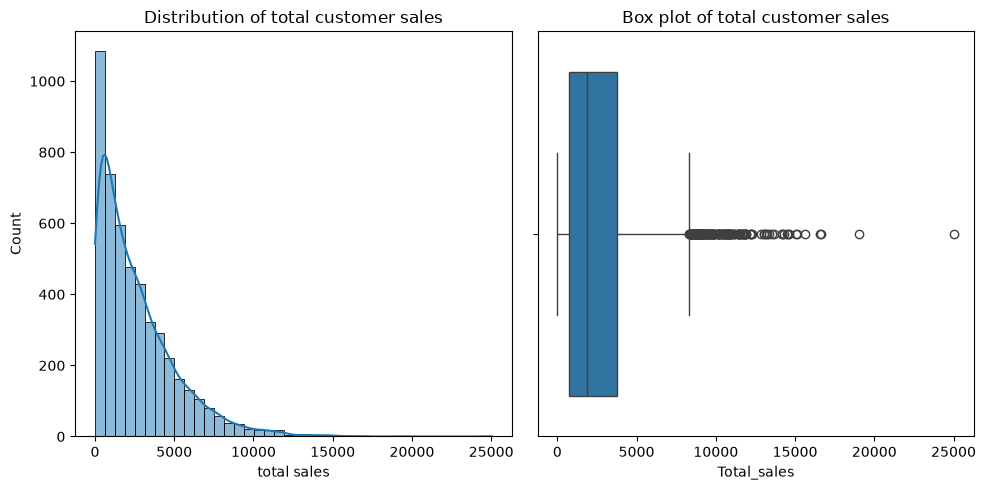

In [54]:
# vizualize the distribution

fig, axes =plt.subplots(1,2, figsize=(10,5))

sns.histplot(
    data=customer_df,
    x="total_sales",
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribution of total customer sales')
axes[0].set_xlabel('total sales')

sns.boxplot(
    data=customer_df,
    x=customer_df["total_sales"],
    ax=axes[1]
        
)

axes[1].set_title('Box plot of total customer sales')
axes[1].set_xlabel('Total_sales')

plt.tight_layout()
plt.show()

**Total profit** – also right-skewed, and some customers are loss-making (negative profit).

In [55]:
# Descriptive statistics

customer_df["total_profit"].describe()

count    4873.000000
mean      301.140425
std       659.884501
min     -6626.389500
25%        10.290000
50%       189.025800
75%       528.414000
max      8981.323900
Name: total_profit, dtype: float64

In [ ]:
#skewness

customer_df["total_profit"].skew() # positvely skewed

np.float64(1.1593912511011952)

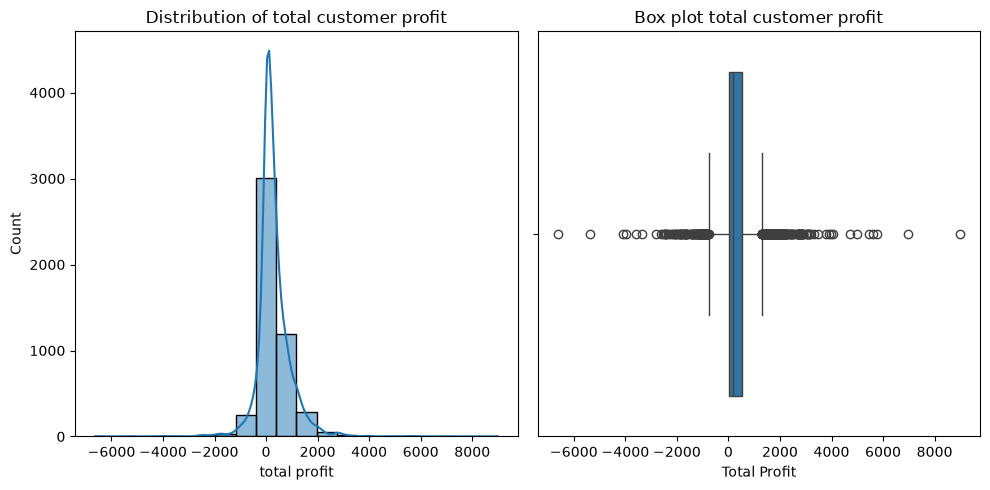

In [68]:
# vizualization

fig, axes=plt.subplots(1,2,figsize=(10,5))

sns.histplot(
        data=customer_df,
        x=customer_df["total_profit"],
        bins=20,
        kde=True,
        ax=axes[0]
)


        

axes[0].set_title("Distribution of total customer profit")
axes[0].set_xlabel("total profit")


sns.boxplot(
        data=customer_df,
        x=customer_df["total_profit"],
        ax=axes[1]          
)

axes[1].set_title("Box plot total customer profit")
axes[1].set_xlabel("Total Profit")



plt.tight_layout()
plt.show()

**Total orders** – fairly symmetric (mean ≈ 5.3, max 18).

In [69]:
#descriptive statistics

customer_df["total_orders"].describe()

count    4873.000000
mean        5.284835
std         2.857330
min         1.000000
25%         3.000000
50%         5.000000
75%         7.000000
max        18.000000
Name: total_orders, dtype: float64

In [70]:
#skewness

customer_df["total_orders"].skew()

np.float64(0.5292749290382951)

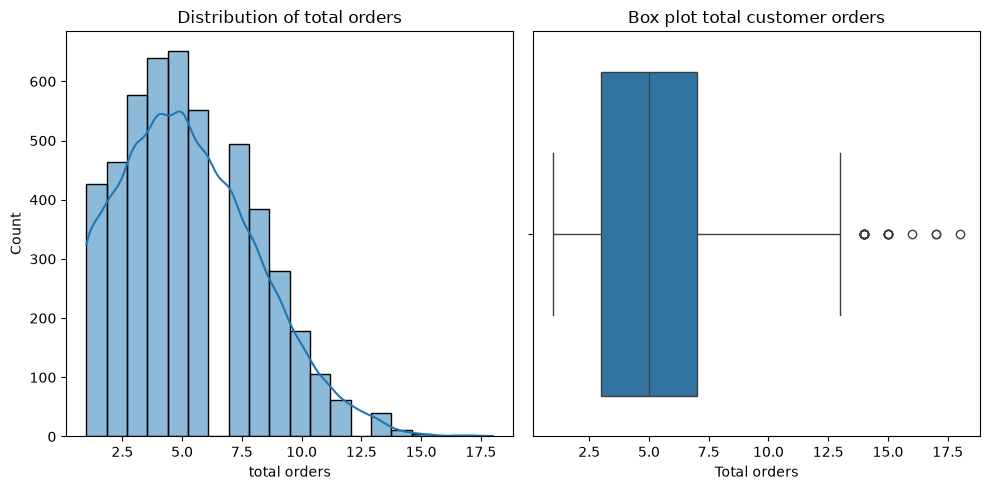

In [ ]:
# vizualization

fig, axes=plt.subplots(1,2,figsize=(10,5))

sns.histplot(
        data=customer_df,
        x=customer_df["total_orders"],
        bins=20,
        kde=True,
        ax=axes[0]
)


        

axes[0].set_title("Distribution of total orders")
axes[0].set_xlabel("total orders")


sns.boxplot(
        data=customer_df,
        x=customer_df["total_orders"],
        ax=axes[1]          
)

axes[1].set_title("Box plot of total customer orders")
axes[1].set_xlabel("Total orders")



plt.tight_layout()
plt.show()

**Average order value (AOV)** – strongly right-skewed because a few customers buy very large baskets.

In [72]:
# Descriptive statistics
customer_df["avg_order_value"].describe()

count    4873.000000
mean      461.205949
std       389.993576
min         2.000000
25%       195.440000
50%       375.430000
75%       617.000000
max      5100.000000
Name: avg_order_value, dtype: float64

In [74]:
#skewness
customer_df["avg_order_value"].skew()

np.float64(2.8365858631082266)

In [ ]:
# vizualization

fig, axes=plt.subplots(1,2,figsize=(10,5))

sns.histplot(
        data=customer_df,
        x=customer_df["avg_order_value"],
        bins=20,
        kde=True,
        ax=axes[0]
)


        

axes[0].set_title("Distribution of average order value")
axes[0].set_xlabel("Average order value")


sns.boxplot(
        data=customer_df,
        x=customer_df["avg_order_value"],
        ax=axes[1]          
)

axes[1].set_title("Box plot of average order value")
axes[1].set_xlabel("Average order value")



plt.tight_layout()
plt.show()

**Recency** (days since last purchase, reference date 2015-01-01) – right-skewed: most customers bought recently, a tail has been inactive for years.

In [83]:
# Descriptive statistics

customer_df["recency"].describe()

count    4873.000000
mean      207.422943
std       254.526205
min         1.000000
25%        42.000000
50%       110.000000
75%       269.000000
max      1460.000000
Name: recency, dtype: float64

In [84]:
#skewness

customer_df["recency"].skew()

np.float64(2.1260186140145683)

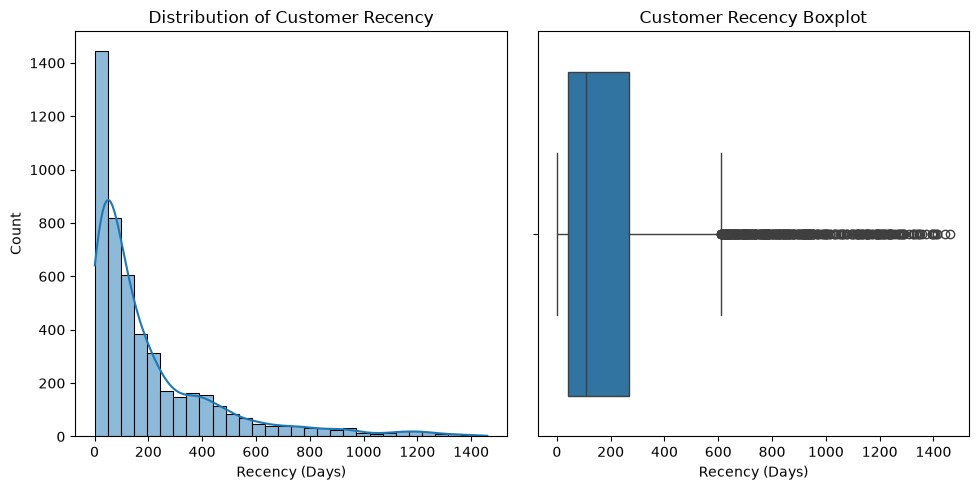

In [85]:
#vizualization

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.histplot(
    data=customer_df,
    x="recency",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Customer Recency")
axes[0].set_xlabel("Recency (Days)")

sns.boxplot(
    data=customer_df,
    x="recency",
    ax=axes[1]
)

axes[1].set_title("Customer Recency Boxplot")
axes[1].set_xlabel("Recency (Days)")

plt.tight_layout()
plt.show()

**Average discount** – most customers receive around 10–15%, with a tail of heavily discounted customers.

In [87]:
customer_df["avg_discount"].describe()

count    4873.000000
mean        0.142415
std         0.136885
min         0.000000
25%         0.040000
50%         0.120000
75%         0.200000
max         0.700000
Name: avg_discount, dtype: float64

In [88]:
customer_df["avg_discount"].skew()

np.float64(1.4723124769440064)

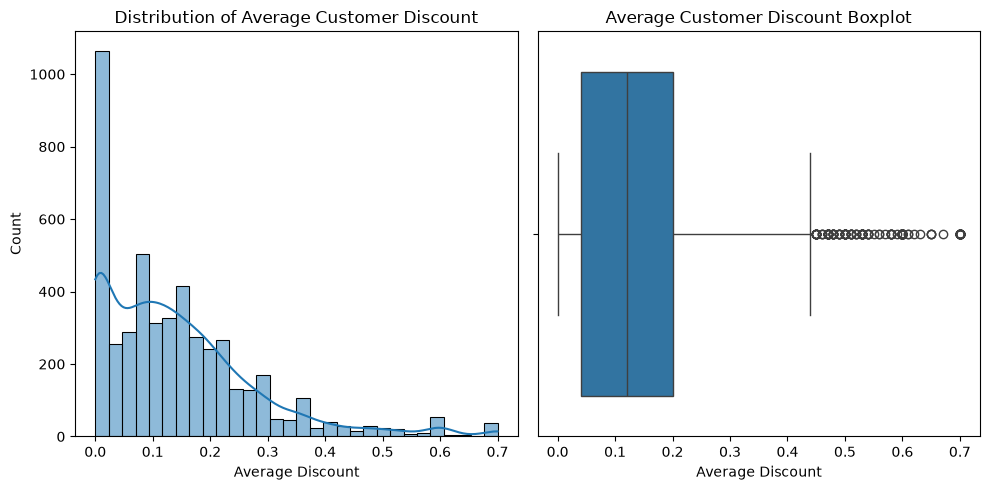

In [89]:
#vizualization

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.histplot(
    data=customer_df,
    x="avg_discount",
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of Average Customer Discount")
axes[0].set_xlabel("Average Discount")

sns.boxplot(
    data=customer_df,
    x="avg_discount",
    ax=axes[1]
)

axes[1].set_title("Average Customer Discount Boxplot")
axes[1].set_xlabel("Average Discount")

plt.tight_layout()
plt.show()

### 6.3 Relationships between features
Pearson measures linear association, Spearman measures rank (monotonic) association. Because the data is skewed, Spearman is the more reliable of the two here.

In [95]:
correlation_columns=[
    "recency",
    "total_orders",
    "total_sales",
    "total_profit",
    "avg_order_value",
    "avg_discount"
]

corr_matrix=customer_df[correlation_columns].corr(method="pearson")

corr_matrix.round(3)

,recency,total_orders,total_sales,total_profit,avg_order_value,avg_discount
recency,1.000,-0.473,-0.302,-0.142,-0.092,-0.022
total_orders,-0.473,1.000,0.649,0.295,0.141,0.006
total_sales,-0.302,0.649,1.000,0.552,0.731,-0.086
total_profit,-0.142,0.295,0.552,1.000,0.449,-0.340
avg_order_value,-0.092,0.141,0.731,0.449,1.000,-0.150
avg_discount,-0.022,0.006,-0.086,-0.340,-0.150,1.000


In [91]:
#sperman correlation

spearman_corr = customer_df[correlation_columns].corr(
    method="spearman"
)

spearman_corr.round(3)

,recency,total_orders,total_sales,total_profit,avg_order_value,avg_discount
recency,1.000,-0.470,-0.348,-0.188,-0.143,-0.123
total_orders,-0.470,1.000,0.736,0.381,0.313,0.212
total_sales,-0.348,0.736,1.000,0.585,0.850,0.070
total_profit,-0.188,0.381,0.585,1.000,0.544,-0.383
avg_order_value,-0.143,0.313,0.850,0.544,1.000,-0.069
avg_discount,-0.123,0.212,0.070,-0.383,-0.069,1.000


Scatter plots of the key pairs. Look for: more orders ↔ more sales, and whether higher average discount goes with lower profit.

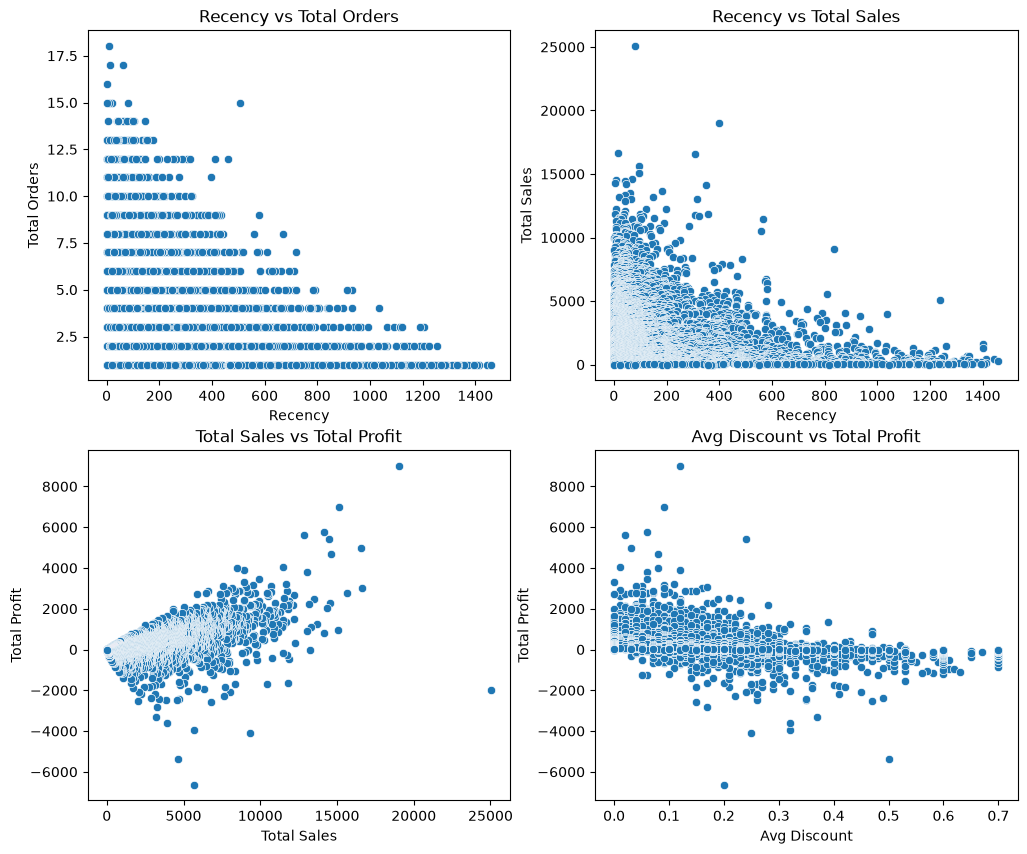

In [96]:
relationships = [
    ("recency","total_orders"),
    ("recency","total_sales"),
    ("total_sales","total_profit"),
    ("avg_discount","total_profit")
]


fig, axes =plt.subplots(2,2,figsize=(12,10))

for ax, (x,y) in zip(axes.flat,relationships):
    sns.scatterplot(
        data=customer_df,
        x=x,
        y=y,
        ax=ax
    )
    
    ax.set_title(f"{x.replace('_',' ').title()} vs {y.replace('_',' ').title()}")
    ax.set_xlabel(x.replace("_"," ").title())
    ax.set_ylabel(y.replace("_"," ").title())

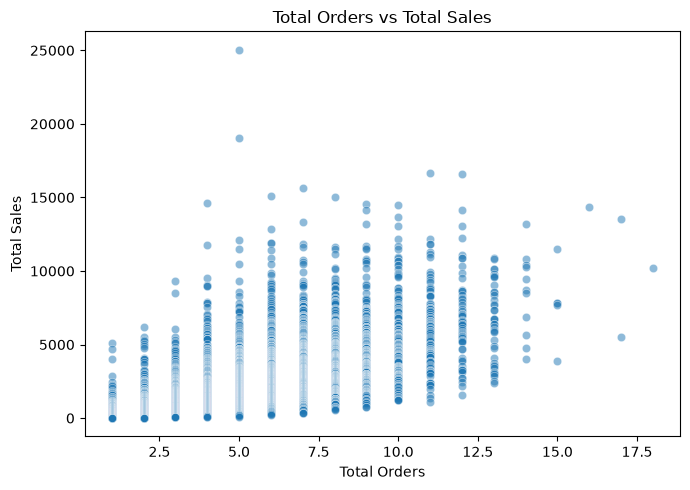

In [97]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=customer_df,
    x="total_orders",
    y="total_sales",
    alpha=0.5
)

plt.title("Total Orders vs Total Sales")
plt.xlabel("Total Orders")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

## 7. Export
Save the customer table for notebooks 02 and 03 (kept out of Git via `.gitignore`).

In [ ]:
# Export the customer-level dataset for notebooks 02 and 03
customer_df.to_csv("customer_features.csv", index=False)